# 05 · Options: what does the market charge for volatility and crash insurance?

An option's price is set by one unobservable input: the volatility the market expects. Inverting Black-Scholes turns every quoted price into an **implied volatility**, and those numbers can be tested against what actually happens.

**Three questions:**
1. **The smile.** Black-Scholes assumes one volatility for every strike. What does the market do instead?
2. **Crash insurance.** How does the price of a 1-month put compare with what such puts actually paid out, using 98 years of market history?
3. **The variance risk premium.** Does implied volatility (VIX) overstate the volatility that follows? If so, what does a seller of delta-hedged options earn from 1990 to 2026, and what does it lose in crashes?

**Data.**
- **Option chain:** a snapshot of SPY option quotes at the close of 30 October 2026, saved in `data/` so the notebook reproduces exactly. Yahoo Finance has no history of option prices.
- **Market history:** VIX (implied volatility of the S&P 500 over the next 30 days) from 1990, S&P 500 and T-bill rates from Yahoo, and French's daily market returns from 1926.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import yfinance as yf

from quant_research.backtest import metrics as mt
from quant_research.data import french, prices
from quant_research.options import black_scholes as bs
from quant_research.options.hedging import hedge
from quant_research.risk import var

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.figsize": (10, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})
pct = plt.FuncFormatter(lambda x, _: f"{x:.0%}")

## 1 · The pricer

`options/black_scholes.py` prices European calls and puts with a dividend yield, computes the five Greeks, inverts prices to implied volatility, and checks itself by Monte Carlo. The tests reproduce Hull's textbook example and match every Greek to finite differences. Here are two checks you can see.

Hull Example 15.6 (S 42, K 40, r 10%, sigma 20%, 6 months): call 4.76 (textbook 4.76), put 0.81 (textbook 0.81)
95% intervals containing the Black-Scholes price, 100 independent runs: 91%


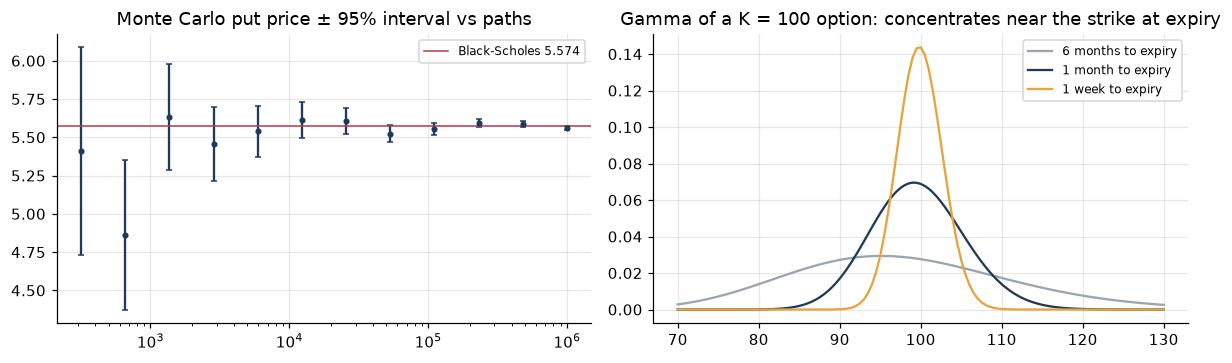

In [2]:
print(f"Hull Example 15.6 (S 42, K 40, r 10%, sigma 20%, 6 months): call {bs.price(42, 40, 0.5, 0.1, 0.2):.2f} "
      f"(textbook 4.76), put {bs.price(42, 40, 0.5, 0.1, 0.2, kind='put'):.2f} (textbook 0.81)")

exact = bs.price(100, 100, 1.0, 0.05, 0.2, kind="put")
ns = np.logspace(2.5, 6, 12).astype(int)
mc = [bs.monte_carlo_price(100, 100, 1.0, 0.05, 0.2, kind="put", n_paths=n, seed=i) for i, n in enumerate(ns)]
cover = [abs(est - exact) < 1.96 * se for est, se in
         (bs.monte_carlo_price(100, 100, 1.0, 0.05, 0.2, kind="put", n_paths=200_000, seed=100 + i) for i in range(100))]
print(f"95% intervals containing the Black-Scholes price, 100 independent runs: {np.mean(cover):.0%}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].errorbar(ns, [m[0] for m in mc], yerr=[1.96 * m[1] for m in mc], fmt="o", color="#1f3b5c", ms=3, capsize=2)
axes[0].axhline(exact, color="#b23a48", lw=1, label=f"Black-Scholes {exact:.3f}")
axes[0].set_xscale("log")
axes[0].set_title("Monte Carlo put price ± 95% interval vs paths")
axes[0].legend(fontsize=8)
spots = np.linspace(70, 130, 121)
for T, c, lbl in ((0.5, "#9aa5b1", "6 months"), (1 / 12, "#1f3b5c", "1 month"), (1 / 52, "#e8a33d", "1 week")):
    axes[1].plot(spots, bs.greeks(spots, 100, T, 0.04, 0.2)["gamma"], color=c, label=f"{lbl} to expiry")
axes[1].set_title("Gamma of a K = 100 option: concentrates near the strike at expiry")
axes[1].legend(fontsize=8)
plt.tight_layout()

The Monte Carlo interval narrows as 1/√paths. Across 100 independent runs the 95% interval contained the exact price 91 times, consistent with 95% given sampling noise (the standard error of a 100-run coverage rate is about 2 points). Gamma (how fast delta changes) piles up at the strike as expiry nears, so a hedged option position is most exposed to realized volatility when the price sits near the strike in the last weeks. That matters in section 4.

## 2 · The smile

Implied volatility of out-of-the-money SPY options (puts below the spot price, calls above), from mid quotes. SPY options are American-style, but for out-of-the-money options early exercise is worth very little, so Black-Scholes is a close approximation.

**The forward price matters.** With the T-bill rate and the trailing dividend yield as inputs, put and call implied vols at the same strike disagree by about 2 points near the money, because those inputs aren't exactly what the market uses (its financing rate, the dividends it expects, quote timing). The standard fix is to back out each expiry's forward price from put-call parity, C − P = e^(−rT)(F − K), using the strikes nearest the money. Puts and calls then agree.

SPY 755.72, risk-free 3.97% (13-week T-bill), dividend yield 1.00% (trailing 12 months)
At-the-money implied vol: {'28 days': '15.7%', '91 days': '16.2%'}


,strike,type,mid,implied vol (ours),implied vol (Yahoo)
moneyness,,,,,
0.8006,605.0000,put,0.6000,0.4045,0.4060
0.8469,640.0000,put,0.9050,0.3399,0.3397
0.8998,680.0000,put,1.6650,0.2696,0.2669
0.9527,720.0000,put,4.0550,0.2066,0.1998
1.0004,756.0000,call,14.7200,0.1575,0.1818
1.0507,794.0000,call,1.0250,0.1195,0.1312
1.0983,830.0000,call,0.0600,0.1299,0.1406


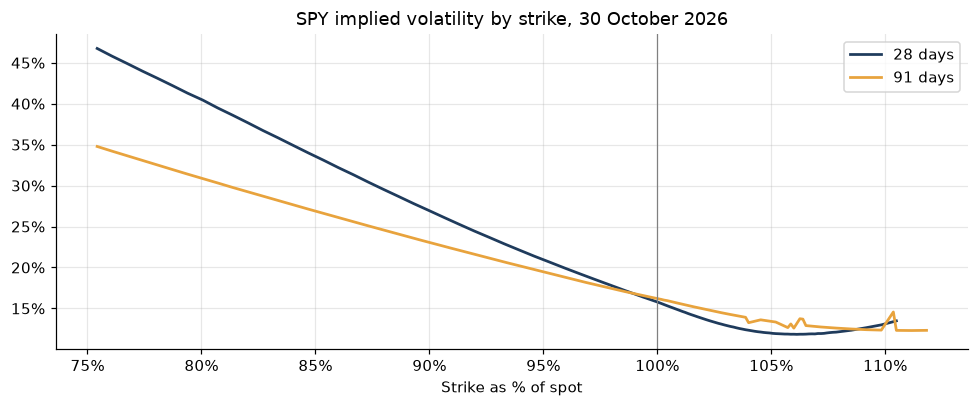

In [3]:
chain = pd.read_csv("../data/spy_options_2026-10-30.csv", parse_dates=["expiry", "quote_date", "lastTradeDate"])
S = float(chain["spot"].iloc[0])
r = float(prices.daily_prices("^IRX", "2026-10-01").loc[:"2026-10-30"].iloc[-1] / 100)
div = yf.Ticker("SPY").dividends
div.index = div.index.tz_localize(None)
q = float(div[(div.index > "2025-10-30") & (div.index <= "2026-10-30")].sum() / S)
print(f"SPY {S:.2f}, risk-free {r:.2%} (13-week T-bill), dividend yield {q:.2%} (trailing 12 months)")

chain["days"] = (chain["expiry"] - chain["quote_date"]).dt.days
chain["T"] = chain["days"] / 365
chain["mid"] = (chain["bid"] + chain["ask"]) / 2


def implied_carry(e):
    # dividend yield q that makes put-call parity hold at the six strikes nearest the money
    both = pd.concat({"c": e[e["type"] == "call"].set_index("strike")["mid"],
                      "p": e[e["type"] == "put"].set_index("strike")["mid"]}, axis=1).dropna()
    near = both.iloc[np.argsort(np.abs(both.index.to_numpy() - S))[:6]]
    T = e["T"].iloc[0]
    F = np.median(near.index.to_numpy() + np.exp(r * T) * (near["c"] - near["p"]).to_numpy())
    return r - np.log(F / S) / T


chain["q"] = chain["expiry"].map({exp: implied_carry(e) for exp, e in chain.groupby("expiry")})
liquid = (chain["bid"] > 0) & (chain["ask"] > chain["bid"]) & ((chain["ask"] - chain["bid"]) / chain["mid"] < 0.5)
otm = ((chain["type"] == "put") & (chain["strike"] < S)) | ((chain["type"] == "call") & (chain["strike"] >= S))
smile = chain[liquid & otm].copy()
smile["iv"] = [bs.implied_vol(m, S, K, T, r, qe, k)
               for m, K, T, qe, k in zip(smile["mid"], smile["strike"], smile["T"], smile["q"], smile["type"])]
smile["moneyness"] = smile["strike"] / S
atm = {d: smile[smile["days"] == d].iloc[np.abs(smile.loc[smile["days"] == d, "moneyness"] - 1).argmin()]["iv"] for d in (28, 91)}
print("At-the-money implied vol:", {f"{d} days": f"{v:.1%}" for d, v in atm.items()})

fig, ax = plt.subplots(figsize=(9, 3.8))
for days, c in ((28, "#1f3b5c"), (91, "#e8a33d")):
    e = smile[(smile["days"] == days) & smile["moneyness"].between(0.75, 1.12)].sort_values("moneyness")
    ax.plot(e["moneyness"], e["iv"], color=c, lw=1.8, label=f"{days} days")
ax.axvline(1, color="grey", lw=0.8)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Strike as % of spot")
ax.set_title("SPY implied volatility by strike, 30 October 2026")
ax.legend()
plt.tight_layout()

one_month = smile[smile["days"] == 28].set_index("moneyness").sort_index()
pick = [one_month.index[np.abs(one_month.index - x).argmin()] for x in (0.80, 0.85, 0.90, 0.95, 1.00, 1.05, 1.10)]
one_month.loc[pick, ["strike", "type", "mid", "iv", "impliedVolatility"]].rename(
    columns={"iv": "implied vol (ours)", "impliedVolatility": "implied vol (Yahoo)"})

**The smile is a skew.** A put 20% below the spot price trades at about 40% implied volatility, the at-the-money option at about 16%, and out-of-the-money calls at about 12%. If Black-Scholes were right, the line would be flat.

The skew is the market pricing what study 03 measured. Returns have fat left tails (crashes) that a normal distribution misses, so protection against large falls costs more than one volatility can explain. It has been a permanent feature of index options since the 1987 crash. Yahoo's implied vols differ from ours by up to a couple of points near the money, because Yahoo uses its own rate and dividend inputs rather than the parity-implied forward.

## 3 · How expensive is crash insurance?

Take the 28-day puts (20 trading days) and compare each price with what the same put would have paid out over every 20-day window since 1926, using French's daily market returns less the SPY dividend yield, discounted at the T-bill rate. Two versions of history:
- **Raw:** every 20-day market move since 1926 as it happened.
- **Scaled to today's volatility:** each historical move rescaled by today's volatility relative to the volatility at that time (the filtered historical method that did best in study 03). Recent realized volatility is low (about 10% annualized), so this version says crashes are less likely now.

In [4]:
mkt = french.load("ff3_daily")
m = (mkt["Mkt-RF"] + mkt["RF"]).dropna()
H, T = 20, 28 / 365
R = (1 + m).rolling(H).apply(np.prod, raw=True).dropna() - 1 - q * T
vol_then = var.ewma_vol(m).shift(H - 1).reindex(R.index)
spx_ret = prices.daily_prices("^GSPC", "2020-01-01").loc[:"2026-10-30"].pct_change().dropna()
vol_now = float(var.ewma_vol(spx_ret).iloc[-1])
R_scaled = R / vol_then * vol_now
print(f"{len(R):,} overlapping 20-day windows since {R.index.min():%Y}; S&P 500 EWMA volatility today "
      f"{vol_now * np.sqrt(252):.1%} a year")

rows = {}
puts = smile[(smile["days"] == 28) & (smile["type"] == "put")].set_index("moneyness").sort_index()
for target in (0.95, 0.90, 0.85, 0.80):
    k = puts.index[np.abs(puts.index - target).argmin()]
    row = puts.loc[k]
    price_pct = row["mid"] / S
    raw = np.exp(-r * T) * np.maximum(k - (1 + R), 0).mean()
    scaled = np.exp(-r * T) * np.maximum(k - (1 + R_scaled), 0).mean()
    d2 = bs._d1d2(1.0, k, T, r, row["iv"], row["q"])[1]
    rows[f"{k:.0%} strike"] = {"price, % of spot": price_pct, "implied vol": row["iv"],
                               "avg historical payout": raw, "price ÷ payout": price_pct / raw,
                               "price ÷ payout, vol-scaled": price_pct / scaled,
                               "P(finish below), priced": bs.N(-d2), "P(finish below), 1926–2026": (1 + R < k).mean()}
insurance = pd.DataFrame(rows).T
insurance.style.format({"price, % of spot": "{:.3%}", "implied vol": "{:.1%}", "avg historical payout": "{:.3%}",
                        "price ÷ payout": "{:.1f}x", "price ÷ payout, vol-scaled": "{:.1f}x",
                        "P(finish below), priced": "{:.1%}", "P(finish below), 1926–2026": "{:.1%}"})

26,319 overlapping 20-day windows since 1926; S&P 500 EWMA volatility today 9.9% a year


,"price, % of spot",implied vol,avg historical payout,price ÷ payout,"price ÷ payout, vol-scaled","P(finish below), priced","P(finish below), 1926–2026"
95% strike,0.537%,20.7%,0.413%,1.3x,2.9x,18.5%,10.3%
90% strike,0.220%,27.0%,0.123%,1.8x,7.3x,7.6%,2.6%
85% strike,0.120%,34.0%,0.043%,2.8x,11.8x,3.9%,0.8%
80% strike,0.079%,40.4%,0.017%,4.7x,15.8x,2.4%,0.4%


**Crash insurance is expensive, and more so the further out of the money.**
- A put 5% below the spot price costs about 1.3 times its average historical payout. A put 20% below costs about 5 times.
- The priced probability of finishing below the strike (the risk-neutral N(−d₂)) is several times the historical frequency for deep out-of-the-money strikes.
- Scaled to today's calm volatility, the prices look 3 to 16 times too high. But study 03 found that volatility-based models fail precisely in calm markets (shocks like 1987 and February 2020 came from them), so the truth likely lies between the two columns.

Two things justify part of the premium:
- **The equity premium.** Real-world prices drift upward, which makes puts pay less than under the risk-neutral pricing measure.
- **Timing.** Insurance pays out exactly when investors are worst off, so they rationally pay more than the expected payout.

The sellers of this insurance are paid for bearing crash risk. Section 4 measures how well.

## 4 · The variance risk premium, 1990–2026

VIX is the market's 30-day implied volatility for the S&P 500. Compare each day's VIX with the volatility the S&P 500 actually showed over the next 21 trading days.

,1990–2026
average VIX,0.1943
average realized,0.1533
share of days VIX > realized,0.8590
"regression: realized = a + b x VIX, b",0.8772
R²,0.5177


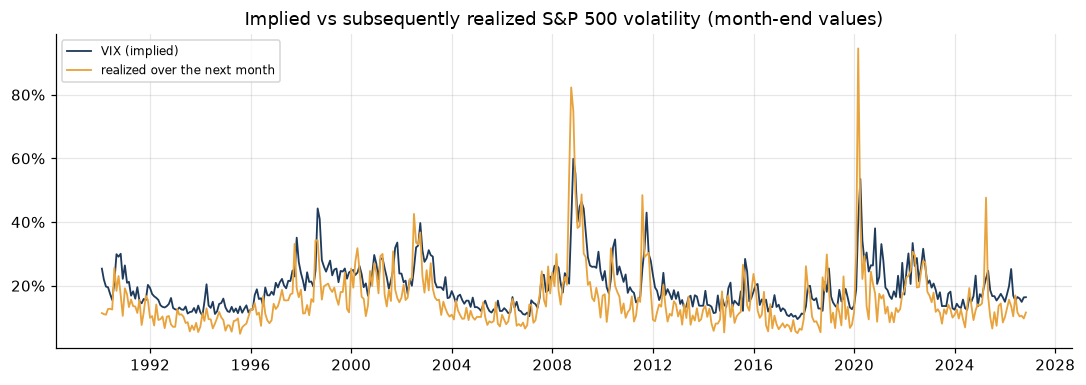

In [5]:
spx = prices.daily_prices("^GSPC", "1989-01-01")
vix = prices.daily_prices("^VIX", "1990-01-01") / 100
irx = prices.daily_prices("^IRX", "1989-01-01") / 100
df = pd.concat({"S": spx, "vix": vix, "r": irx}, axis=1).dropna(subset=["S"]).ffill().dropna()
df = df[df.index <= "2026-10-30"]
fwd = np.sqrt((np.log(df["S"]).diff() ** 2).rolling(21).mean().shift(-21) * 252)
vrp = pd.DataFrame({"VIX": df["vix"], "realized next 21 days": fwd}).dropna()

fig, ax = plt.subplots(figsize=(10, 3.6))
monthly_vrp = vrp.resample("ME").last()
ax.plot(monthly_vrp.index, monthly_vrp["VIX"], color="#1f3b5c", lw=1.2, label="VIX (implied)")
ax.plot(monthly_vrp.index, monthly_vrp["realized next 21 days"], color="#e8a33d", lw=1.2, label="realized over the next month")
ax.yaxis.set_major_formatter(pct)
ax.set_title("Implied vs subsequently realized S&P 500 volatility (month-end values)")
ax.legend(fontsize=8)
plt.tight_layout()

fit = sm.OLS(vrp["realized next 21 days"], sm.add_constant(vrp["VIX"])).fit(cov_type="HAC", cov_kwds={"maxlags": 21})
pd.Series({"average VIX": vrp["VIX"].mean(), "average realized": vrp["realized next 21 days"].mean(),
           "share of days VIX > realized": (vrp["VIX"] > vrp["realized next 21 days"]).mean(),
           "regression: realized = a + b x VIX, b": fit.params["VIX"], "R²": fit.rsquared}).to_frame("1990–2026")

**VIX overstates the volatility that follows about 85% of the time**, by 4 volatility points on average (19% against 15%). It is still a good forecast: it explains about half of the variation in realized volatility, with a regression slope a little below 1 (0.88). The gap is a premium, not a forecasting error: buyers pay up for protection, as in section 3.

The exceptions are the shocks. In 2008 and February 2020 realized volatility reached 80–95% against a VIX of about 40%, and shorter episodes followed the same pattern in 2002, 2011, 2015 and 2025.

### Two ways to sell volatility

**1. A variance swap.** The seller receives a fixed variance (the strike) and pays the realized variance over the month. VIX is computed as the fair strike of a 30-day S&P 500 variance swap, so this test needs no assumption about the selling price: the seller receives VIX² and pays realized variance. P&L is shown per $1 of vega notional (the gain from a one-point fall in volatility). A second version gives up one volatility point to the bid-ask spread.

In [6]:
H = 21
rows = []
for i in range(0, len(df) - H, H):
    w = df.iloc[i:i + H + 1]
    rows.append({"date": w.index[0], "vix": w["vix"].iloc[0],
                 "realized_var": (np.log(w["S"]).diff().dropna() ** 2).sum() * 252 / H})
swaps = pd.DataFrame(rows).set_index("date")
var_swap = {}
for label, cost in (("strike = VIX", 0.0), ("strike = VIX − 1 (bid-ask)", 0.01)):
    pnl = ((swaps["vix"] - cost) ** 2 - swaps["realized_var"]) / (2 * swaps["vix"]) / 12
    s = mt.summary(pnl)
    var_swap[label] = {"P&L / yr (per $1 vega)": pnl.mean() * 12, "Sharpe": s["Sharpe"], "% months positive": s["% months > 0"],
                       "skew": s["skew"], "worst month": s["worst month"], "worst month date": f"{pnl.idxmin():%Y-%m}"}
pd.DataFrame(var_swap).T

,P&L / yr (per $1 vega),Sharpe,% months positive,skew,worst month,worst month date
strike = VIX,0.0273,1.1933,0.8435,-6.1539,-0.0741,2020-03
strike = VIX − 1 (bid-ask),0.0176,0.7688,0.8050,-6.1581,-0.0749,2020-03


Selling variance at the VIX level earned a Sharpe ratio of about 1.2 over 36 years, and still about 0.8 after a one-point bid-ask cost. It was positive in about four months out of five. The skew of about −6 is the catch: almost all the risk sits in a few months, led by March 2020.

**2. A delta-hedged straddle.** Every 21 trading days, sell a 1-month at-the-money straddle (a call plus a put) on the S&P 500, and hedge it daily with Black-Scholes deltas (`options/hedging.py`). The hedge removes market direction, so the seller earns when realized volatility is below implied and loses when it is above, weighted by gamma. P&L is per $1 of index notional, with 2% of the premium paid in bid-ask spread.

Unlike the variance swap, the straddle trades at the **at-the-money** implied vol, and that is not VIX. VIX includes the expensive out-of-the-money puts, so it sits above at-the-money vol: 19.4 against 15.7 on 30 October 2026. Without option history, the at-the-money vol of past months is unknown, so the test sells at VIX minus a range of gaps.

In [7]:
def straddles(vol_shift=0.0, cost=0.02, offset=0, H=21):
    rows = []
    for i in range(offset, len(df) - H, H):
        w = df.iloc[i:i + H + 1]
        S0, sigma = w["S"].iloc[0], max(w["vix"].iloc[0] - vol_shift, 0.05)
        h = hedge(w["S"], S0, sigma, w["r"].iloc[0])
        rows.append({"date": w.index[0], "vix": w["vix"].iloc[0], "realized": h["realized_vol"],
                     "premium": h["premium"] / S0, "pnl": (h["pnl"] - cost * h["premium"]) / S0,
                     "approx": h["approx_pnl"] / S0})
    return pd.DataFrame(rows).set_index("date")

shifts = [0.0, 0.01, 0.02, 0.03, 0.04]
runs = {sh: straddles(vol_shift=sh) for sh in shifts}
curve = pd.DataFrame({f"VIX − {sh * 100:.0f}": {"P&L / yr (per $1 notional)": x["pnl"].mean() * 12,
                                               "Sharpe": x["pnl"].mean() / x["pnl"].std() * 12 ** 0.5,
                                               "% months positive": (x["pnl"] > 0).mean(), "worst month": x["pnl"].min()}
                      for sh, x in runs.items()}).T
display(curve.style.format({"P&L / yr (per $1 notional)": "{:+.1%}", "Sharpe": "{:.2f}", "% months positive": "{:.0%}",
                            "worst month": "{:.1%}"}))
pnl_by_shift = curve["P&L / yr (per $1 notional)"].to_numpy()
break_even = np.interp(0, pnl_by_shift[::-1], np.array(shifts)[::-1])
print(f"Break-even: selling at about VIX − {break_even * 100:.1f} points; gap on 30 October 2026: {19.42 - atm[28] * 100:.1f} points")

,P&L / yr (per $1 notional),Sharpe,% months positive,worst month
VIX − 0,+10.0%,2.56,82%,-7.2%
VIX − 1,+7.3%,1.91,78%,-7.1%
VIX − 2,+4.6%,1.23,71%,-7.1%
VIX − 3,+1.9%,0.52,63%,-7.0%
VIX − 4,-0.8%,-0.21,51%,-7.0%


Break-even: selling at about VIX − 3.7 points; gap on 30 October 2026: 3.7 points


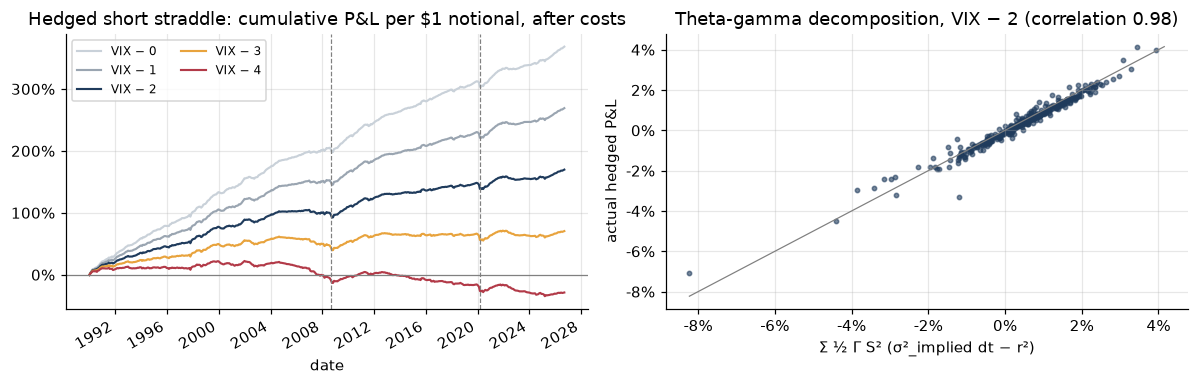

In [8]:
realistic = runs[0.02]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for sh, c in zip(shifts, ["#c9d1d9", "#9aa5b1", "#1f3b5c", "#e8a33d", "#b23a48"]):
    runs[sh]["pnl"].cumsum().plot(ax=axes[0], color=c, lw=1.4, label=f"VIX − {sh * 100:.0f}")
for d in ("2008-09-01", "2020-03-01"):
    axes[0].axvline(pd.Timestamp(d), color="grey", lw=0.8, ls="--")
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].yaxis.set_major_formatter(pct)
axes[0].set_title("Hedged short straddle: cumulative P&L per $1 notional, after costs")
axes[0].legend(fontsize=8, ncol=2)
axes[1].scatter(realistic["approx"], realistic["pnl"], s=8, color="#1f3b5c", alpha=0.6)
lim = [realistic[["approx", "pnl"]].min().min(), realistic[["approx", "pnl"]].max().max()]
axes[1].plot(lim, lim, color="grey", lw=0.8)
axes[1].xaxis.set_major_formatter(pct)
axes[1].yaxis.set_major_formatter(pct)
axes[1].set_xlabel("Σ ½ Γ S² (σ²_implied dt − r²)")
axes[1].set_ylabel("actual hedged P&L")
axes[1].set_title(f"Theta-gamma decomposition, VIX − 2 (correlation {np.corrcoef(realistic['approx'], realistic['pnl'])[0, 1]:.2f})")
plt.tight_layout()

- **The straddle's result depends entirely on the selling price.** Sold at VIX it looks spectacular, but every volatility point below VIX takes away about 2.7% a year. It breaks even at roughly VIX − 3.7, which is about the gap observed on 30 October 2026. One snapshot can't say what the gap averaged since 1990: the skew was flatter in some periods and steeper in others. The textbook "sell at VIX" result mostly reflects the gap between VIX and the price an option seller actually receives.
- **The variance swap is the cleaner test**, because its strike *is* VIX, and it shows a real premium (Sharpe about 0.8–1.2). The difference between the two tells you where the premium sits: much of it is in the out-of-the-money puts that VIX includes and the at-the-money straddle doesn't. That matches section 3.
- **The P&L really is a volatility bet.** The theta-gamma formula, ½ΓS² × (implied minus realized variance) summed over days, explains almost all of the hedged P&L (right panel).

**How bad can one month be?** The 21-day blocks start on 2 January 1990, which is arbitrary. For the VIX − 2 version, moving the start by 0–20 days gives 21 different calendars:

In [9]:
alignments = pd.concat({o: straddles(vol_shift=0.02, offset=o) for o in range(21)}, names=["offset"])
by_offset = alignments.groupby("offset")["pnl"].agg(mean="mean", sd="std", worst="min")
by_offset["Sharpe"] = by_offset["mean"] / by_offset["sd"] * 12 ** 0.5
by_offset["P&L / yr"] = by_offset["mean"] * 12
display(by_offset[["P&L / yr", "Sharpe", "worst"]].describe().loc[["mean", "min", "max"]].style.format("{:.3f}"))
alignments.reset_index().nsmallest(5, "pnl")[["date", "vix", "realized", "pnl"]].style.format(
    {"vix": "{:.0%}", "realized": "{:.0%}", "pnl": "{:.1%}"}, subset=["vix", "realized", "pnl"])

,P&L / yr,Sharpe,worst
mean,0.049,1.209,-0.083
min,0.046,1.076,-0.104
max,0.053,1.299,-0.047


,date,vix,realized,pnl
3311,2008-09-09 00:00:00,25%,58%,-10.4%
1244,2020-03-09 00:00:00,54%,91%,-10.1%
1988,2008-09-04 00:00:00,24%,54%,-10.1%
7856,2020-02-28 00:00:00,40%,94%,-9.9%
3752,2008-09-10 00:00:00,25%,64%,-9.9%


The average return and the Sharpe ratio barely depend on the calendar. **The worst month does**: from −5% to −10% of notional. The worst cases sold volatility at 24–25% in early September 2008, just before realized volatility reached nearly 60%, or in March 2020 at VIX 40–54%, when it reached over 90%. A single month like that costs about two years of income.

## Conclusions

| Question | Answer |
|---|---|
| Does Black-Scholes price the whole surface? | No. SPY implied vol runs from about 40% for puts 20% below spot down to about 12% for calls above: the market prices fat left tails |
| Is crash insurance expensive? | Yes, increasingly with distance from the spot price: 1.3x the historical average payout at 5% out of the money, about 5x at 20%. More if today's calm volatility is believed |
| Does implied volatility overstate realized? | 85% of the time, by about 4 points (VIX 19% against 15%), while still forecasting it well (R² ≈ 0.5) |
| What does selling it earn? | Variance swaps (strike = VIX): Sharpe about 1.2, or 0.8 after a one-point spread, with skew −6. Hedged at-the-money straddles: break even only if sold above roughly VIX − 3.7, about today's VIX-to-ATM gap. The premium sits mostly in the out-of-the-money puts |
| What is the catch? | Crashes. September 2008 and March 2020 each cost 5–10% of notional in a month, about two years of income |

**How this fits the other studies.** Every strategy in this repo is a bet on how prices behave after shocks:
- **Momentum** (study 02) bets that trends continue, and crashes when they reverse.
- **Pairs** (study 04) bets that gaps close, and made most of its money in 2008–09.
- **Short volatility** (this study) bets that calm continues, and lost most in 2008 and 2020.
- **Risk models** (study 03) miss most in the calm periods before those shocks.

A risk team would combine them knowing that their payoffs depend on the same few crisis months.